# Adsorptive Desulfurization Sorbents: Capacity Modeling
## 1. Exploratory Data Analysis

This notebook characterizes the sulfur-adsorption capacity data and identifies which raw features are associated with capacity, and where the structure of the data (confounded variables, repeated materials) constrains modeling. The findings inform feature engineering (`02_feature_engineering.ipynb`) and the evaluation design (`03_modeling.ipynb`).

Dataset: 56 measurements compiled from published sources, described in `../README.md`.

Scope: `capacity_mgS_g` only, the directly reported saturation capacity (n=36 after one exclusion described below). `breakthrough_mL_g` is a distinct quantity and is not modeled in this project.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/adsorptive_desulfurization_dataset.csv')
print(f"Full dataset: {len(df)} rows, {df['source_paper'].nunique()} source papers")
df.head()

Full dataset: 56 rows, 5 source papers


,material,sorbent_class,source_paper,source_page,value_type,metal_1,metal_1_wt_pct,metal_2,metal_2_wt_pct,RE_type,RE_wt_pct,Cu_wt_pct,BET_total_m2g,BET_micro_m2g,BET_meso_m2g,Vtotal_cm3g,Vmicro_cm3g,Vmeso_cm3g,inorganic_P_wt_pct,inorganic_Ca_wt_pct,inorganic_K_wt_pct,inorganic_Na_wt_pct,carbon_C_wt_pct,carbon_H_wt_pct,carbon_N_wt_pct,oxygen_O_wt_pct,sulfur_compound,feed_conc_ppmw,solvent,co_adsorbate,capacity_mgS_g,breakthrough_mL_g,notes,target_available,ID_IG_ratio
0,SAY,zeolite_SAY,Lee2019_IECR_acs.iecr.9b02346,6-7,approx,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DMDBT,100,n-octane,none,NaN,150.0,Read from Fig.9 breakthrough curve (no naphtha...,breakthrough_mL_g,NaN
1,CuSAY,zeolite_SAY,Lee2019_IECR_acs.iecr.9b02346,6-7,approx,Cu,4.6,NaN,NaN,NaN,0.0,4.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DMDBT,100,n-octane,none,NaN,175.0,ICP metal wt% from Table 1; capacity from Fig.9,breakthrough_mL_g,NaN
2,CuCeSAY,zeolite_SAY,Lee2019_IECR_acs.iecr.9b02346,6-7,approx,Cu,2.7,Ce,3.1,Ce,3.1,2.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DMDBT,100,n-octane,none,NaN,200.0,ICP metal wt% from Table 1; capacity from Fig.9,breakthrough_mL_g,NaN
3,2Ce2CuSAY,zeolite_SAY,Lee2019_IECR_acs.iecr.9b02346,7,exact,Ce,1.9,Cu,1.9,Ce,1.9,1.9,663.0,409.0,253.0,0.552,0.190,0.362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DMDBT,100,n-octane,naphthalene_1wt%,NaN,20.0,Ce introduced before Cu (reverse order) BET/po...,breakthrough_mL_g,NaN
4,2Cu2CeSAY,zeolite_SAY,Lee2019_IECR_acs.iecr.9b02346,7,exact,Cu,1.7,Ce,1.6,Ce,1.6,1.7,664.0,406.0,259.0,0.543,0.188,0.355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DMDBT,100,n-octane,naphthalene_1wt%,NaN,35.0,BET/pore data added from SI Table S1 (page S3).,breakthrough_mL_g,NaN


## 1. Isolate the capacity_mgS_g subset


In [2]:
cap = df[df['capacity_mgS_g'].notna()].copy()
print(f"Capacity subset: {len(cap)} rows")
cap[['material','source_paper','sorbent_class','sulfur_compound','capacity_mgS_g','value_type']]

Capacity subset: 37 rows


,material,source_paper,sorbent_class,sulfur_compound,capacity_mgS_g,value_type
5,2Cu10CeSAY,Lee2019_IECR_acs.iecr.9b02346,zeolite_SAY,DMDBT,6.80,exact
20,LaY,Lee2021_JPCC,zeolite_Y,BT,0.64,approx
21,NdY,Lee2021_JPCC,zeolite_Y,BT,0.60,approx
22,SmY,Lee2021_JPCC,zeolite_Y,BT,0.50,approx
23,CeY,Lee2021_JPCC,zeolite_Y,BT,0.84,exact
24,CuLaY,Lee2021_JPCC,zeolite_Y,BT,1.23,approx
25,CuNdY,Lee2021_JPCC,zeolite_Y,BT,1.40,approx
26,CuSmY,Lee2021_JPCC,zeolite_Y,BT,0.85,approx
27,CuCeY,Lee2021_JPCC,zeolite_Y,BT,1.76,exact
28,LaSAY,Lee2021_JPCC,zeolite_SAY,DBT,1.00,approx


## 1b. Exclusion of a confounded zeolite point

`2Cu10CeSAY` is excluded from the zeolite analysis. It is the only zeolite tested with DMDBT (all other zeolites were tested with BT or DBT), has the highest RE loading (8.0 wt%) and the lowest Cu loading (0.9 wt%) among the bimetallic zeolites, and originates from a different source (Lee et al., 2019) than the rest of the RE-loading series (Lee et al., 2021). Sulfur compound, RE loading, Cu loading and source are therefore confounded in this single observation, which cannot support a conclusion on its own. The row remains in the master dataset.

In [3]:
cap = cap[cap['material'] != '2Cu10CeSAY'].copy()
print(f"Capacity subset after exclusion: {len(cap)} rows")

Capacity subset after exclusion: 36 rows


## 2. Sample size and class balance


In [4]:
print("Rows by sorbent class:")
print(cap['sorbent_class'].value_counts())
print()
print("Unique materials by sorbent class:")
print(cap.groupby('sorbent_class')['material'].nunique())
print()
print("value_type breakdown (exact = stated number, approx = read from a figure or stated as a bound):")
print(cap['value_type'].value_counts())

Rows by sorbent class:
sorbent_class
activated_carbon    20
zeolite_Y            8
zeolite_SAY          8
Name: count, dtype: int64

Unique materials by sorbent class:
sorbent_class
activated_carbon    10
zeolite_SAY          8
zeolite_Y            8
Name: material, dtype: int64

value_type breakdown (exact = stated number, approx = read from a figure or stated as a bound):
value_type
exact     21
approx    15
Name: count, dtype: int64


## 3. Confounding between sulfur compound and sorbent class

In [5]:
ctab = pd.crosstab(cap['sorbent_class'], cap['sulfur_compound'])
print(ctab)

sulfur_compound   BT  DBT  DMDBT
sorbent_class                   
activated_carbon   0   10     10
zeolite_SAY        0    8      0
zeolite_Y          8    0      0


BT was tested only on plain Y zeolites, and DBT and DMDBT only on mesoporous SAY. This follows from the experimental design: the micropore openings of Y are too small to admit the bulkier DBT and DMDBT molecules. The co-adsorbate also differs between these groups (20 wt% benzene with BT on Y; 1 wt% naphthalene with DBT on SAY). Sorbent class, sulfur compound and co-adsorbate therefore cannot be separated in this dataset.

## 4. Capacity distribution overall and by group

In [6]:
print(cap['capacity_mgS_g'].describe())
print()
print("By sorbent class:")
print(cap.groupby('sorbent_class')['capacity_mgS_g'].agg(['count','mean','std','min','max']))
print()
print("By sulfur compound:")
print(cap.groupby('sulfur_compound')['capacity_mgS_g'].agg(['count','mean','std','min','max']))

count    36.000000
mean      3.668611
std       2.708121
min       0.500000
25%       1.075000
50%       3.550000
75%       5.325000
max      10.200000
Name: capacity_mgS_g, dtype: float64

By sorbent class:
                  count    mean       std  min    max
sorbent_class                                        
activated_carbon     20  5.5125  2.153936  2.0  10.20
zeolite_SAY           8  1.7500  1.297250  0.7   4.20
zeolite_Y             8  0.9775  0.443066  0.5   1.76

By sulfur compound:
                 count      mean       std  min    max
sulfur_compound                                       
BT                   8  0.977500  0.443066  0.5   1.76
DBT                 18  3.269444  1.845753  0.7   6.30
DMDBT               10  6.540000  2.452754  2.0  10.20


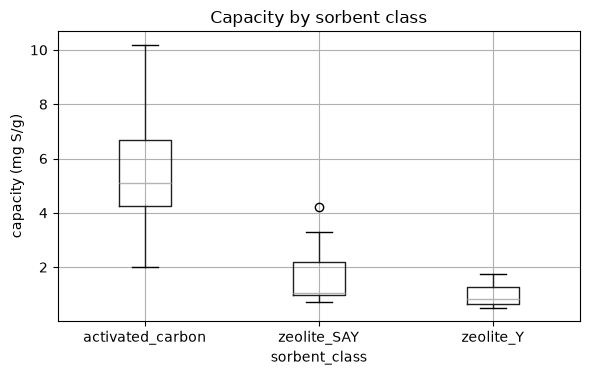

In [7]:
fig, ax = plt.subplots(figsize=(6,4))
cap.boxplot(column='capacity_mgS_g', by='sorbent_class', ax=ax)
ax.set_ylabel('capacity (mg S/g)')
ax.set_title('Capacity by sorbent class')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../reports/capacity_by_class.png', dpi=120)
plt.show()

Capacity also depends on the sulfur compound, co-adsorbates and feed concentration, which differ between these groups, so the distributions are not directly comparable.

## 5. Associations with textural and compositional features, by material family

Correlations are computed separately for each material family to avoid the sorbent-class confound described above.

In [8]:
ac = cap[cap['sorbent_class'] == 'activated_carbon']
zeo = cap[cap['sorbent_class'] != 'activated_carbon']

ac_feats = ['BET_total_m2g','BET_micro_m2g','BET_meso_m2g','Vtotal_cm3g','Vmicro_cm3g','Vmeso_cm3g',
            'inorganic_P_wt_pct','inorganic_Ca_wt_pct','inorganic_K_wt_pct','inorganic_Na_wt_pct',
            'carbon_C_wt_pct','carbon_H_wt_pct','carbon_N_wt_pct','oxygen_O_wt_pct','ID_IG_ratio']
print("Activated carbons (n=20):")
print(ac[ac_feats + ['capacity_mgS_g']].corr()['capacity_mgS_g'].drop('capacity_mgS_g').sort_values(key=abs, ascending=False))

Activated carbons (n=20):
ID_IG_ratio            0.596814
carbon_H_wt_pct       -0.562100
Vmicro_cm3g            0.524128
BET_micro_m2g          0.514916
inorganic_K_wt_pct     0.496995
BET_total_m2g          0.198556
oxygen_O_wt_pct       -0.184220
inorganic_Na_wt_pct    0.181815
BET_meso_m2g          -0.160381
inorganic_P_wt_pct     0.098917
carbon_N_wt_pct       -0.097123
carbon_C_wt_pct        0.092678
Vmeso_cm3g            -0.059325
Vtotal_cm3g            0.053288
inorganic_Ca_wt_pct    0.046845
Name: capacity_mgS_g, dtype: float64


The Raman D/G band ratio showed the strongest association with capacity (r = 0.60), followed by hydrogen content (r = -0.56), micropore volume and area (r = 0.52 and 0.51) and potassium content (r = 0.50). Carbon and nitrogen content showed almost no association (r = 0.09 and -0.10). Because each of the 10 materials contributes two rows, the row-level coefficients count those materials twice; the next cell recomputes the ID/IG association at the material level and within each compound. The activated-carbon set contains only 10 distinct materials, so these coefficients are descriptive.

In [9]:
mat = ac.groupby('material').agg(capacity=('capacity_mgS_g', 'mean'), ID_IG=('ID_IG_ratio', 'first'))
print(f"ID/IG vs. mean capacity per material (n={len(mat)}): r = {mat['capacity'].corr(mat['ID_IG']):.2f}")
for compound, g in ac.groupby('sulfur_compound'):
    print(f"ID/IG vs. capacity within {compound} (n={len(g)}): r = {g['capacity_mgS_g'].corr(g['ID_IG_ratio']):.2f}")

ID/IG vs. mean capacity per material (n=10): r = 0.74
ID/IG vs. capacity within DBT (n=10): r = 0.84
ID/IG vs. capacity within DMDBT (n=10): r = 0.67


At the material level, ID/IG and capacity were correlated at r = 0.74, and within a single sulfur compound at r = 0.84 (DBT, n = 10) and r = 0.67 (DMDBT, n = 10). The association is therefore not an artifact of counting materials twice or of the DBT-DMDBT offset.

In [10]:
ac_nc = ac[ac['material'] != 'CAC']
mat_nc = mat.drop('CAC')
print(f"Without CAC, row level (n={len(ac_nc)}): r = {ac_nc['capacity_mgS_g'].corr(ac_nc['ID_IG_ratio']):.2f}")
print(f"Without CAC, material level (n={len(mat_nc)}): r = {mat_nc['capacity'].corr(mat_nc['ID_IG']):.2f}")
for compound, g in ac_nc.groupby('sulfur_compound'):
    print(f"Without CAC, within {compound} (n={len(g)}): r = {g['capacity_mgS_g'].corr(g['ID_IG_ratio']):.2f}")
print()
print(mat.sort_values('capacity').round(2))

Without CAC, row level (n=18): r = 0.36
Without CAC, material level (n=9): r = 0.50
Without CAC, within DBT (n=9): r = 0.70
Without CAC, within DMDBT (n=9): r = 0.37

          capacity  ID_IG
material                 
CAC           2.15    1.1
FWAC65        3.45    2.1
FWAC55        4.68    2.2
FWAC45        5.30    2.4
FWAC15        5.45    2.1
WAC           5.80    1.8
CoAC          6.05    2.0
MisAC         6.90    1.9
FWAC35        7.10    2.6
FWAC25        8.25    2.9


Removing the commercial carbon CAC, which has both the lowest capacity (2.15 mg S/g) and the lowest ID/IG (1.1) of the ten materials, weakened the association (r = 0.36 by row, 0.50 by material, 0.70 within DBT with n = 9, 0.37 within DMDBT with n = 9). The pooled association therefore depends partly on CAC as a single extreme point, and the positive trend among the remaining nine materials is weaker and noisier.

### Activated carbons: capacity against individual features

Points are colored by sulfur compound.

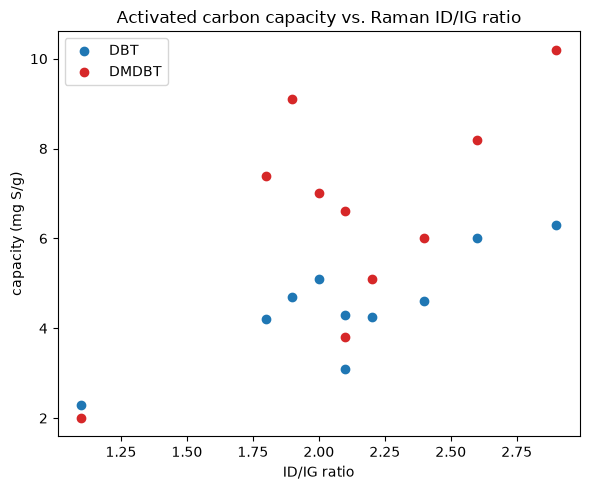

In [11]:
fig, ax = plt.subplots(figsize=(6,5))
colors = {'DBT': 'tab:blue', 'DMDBT': 'tab:red'}
for compound, g in ac.groupby('sulfur_compound'):
    ax.scatter(g['ID_IG_ratio'], g['capacity_mgS_g'], label=compound, color=colors.get(compound, 'tab:gray'))
ax.set_xlabel('ID/IG ratio')
ax.set_ylabel('capacity (mg S/g)')
ax.set_title('Activated carbon capacity vs. Raman ID/IG ratio')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/ac_capacity_vs_id_ig.png', dpi=120)
plt.show()


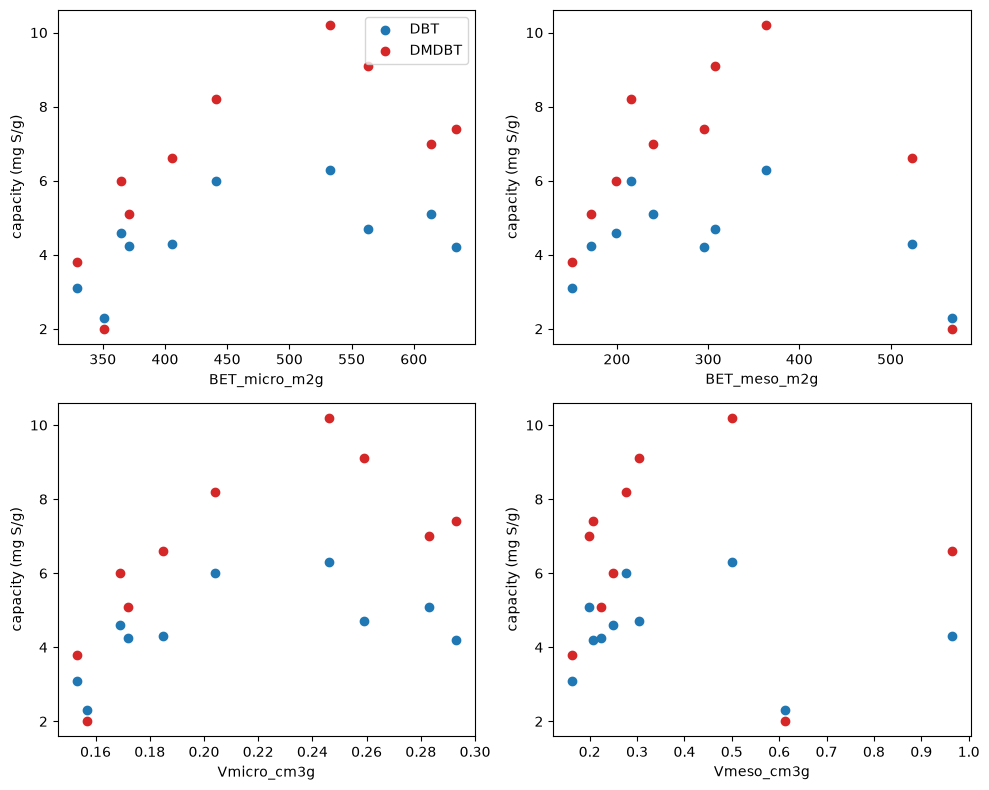

In [12]:
bet_pore_feats = ['BET_micro_m2g', 'BET_meso_m2g', 'Vmicro_cm3g', 'Vmeso_cm3g']
fig, axes = plt.subplots(2, 2, figsize=(10,8))
for ax, feat in zip(axes.flat, bet_pore_feats):
    for compound, g in ac.groupby('sulfur_compound'):
        ax.scatter(g[feat], g['capacity_mgS_g'], label=compound, color=colors.get(compound, 'tab:gray'))
    ax.set_xlabel(feat)
    ax.set_ylabel('capacity (mg S/g)')
axes.flat[0].legend()
plt.tight_layout()
plt.savefig('../reports/ac_capacity_vs_bet_pore.png', dpi=120)
plt.show()


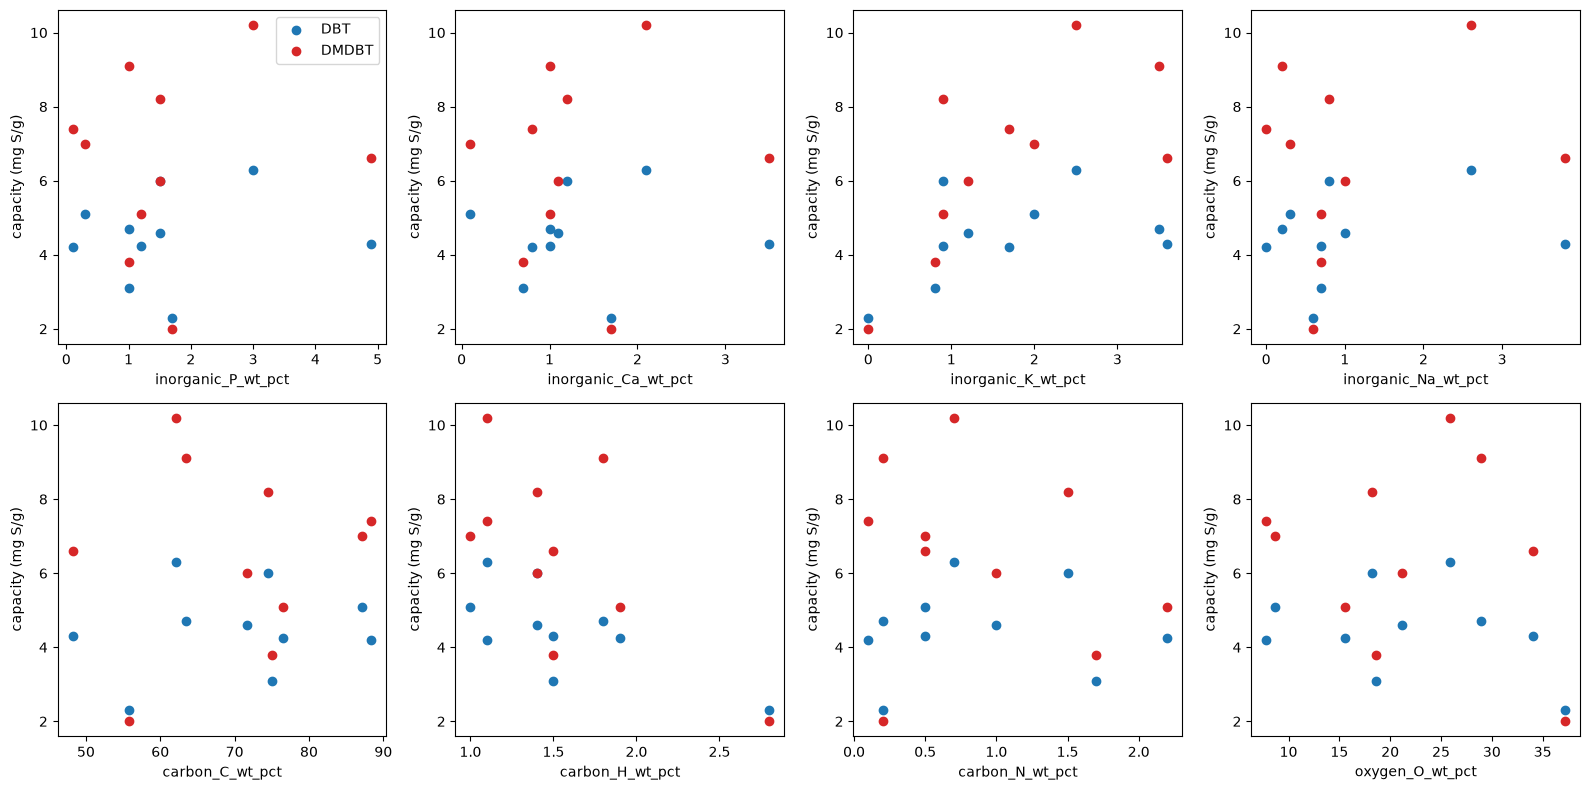

In [13]:
elemental_feats = ['inorganic_P_wt_pct', 'inorganic_Ca_wt_pct', 'inorganic_K_wt_pct', 'inorganic_Na_wt_pct',
                    'carbon_C_wt_pct', 'carbon_H_wt_pct', 'carbon_N_wt_pct', 'oxygen_O_wt_pct']
fig, axes = plt.subplots(2, 4, figsize=(16,8))
for ax, feat in zip(axes.flat, elemental_feats):
    for compound, g in ac.groupby('sulfur_compound'):
        ax.scatter(g[feat], g['capacity_mgS_g'], label=compound, color=colors.get(compound, 'tab:gray'))
    ax.set_xlabel(feat)
    ax.set_ylabel('capacity (mg S/g)')
axes.flat[0].legend()
plt.tight_layout()
plt.savefig('../reports/ac_capacity_vs_elemental.png', dpi=120)
plt.show()


In [14]:
zeo_feats = ['BET_total_m2g','Vtotal_cm3g','Vmicro_cm3g','Vmeso_cm3g','RE_wt_pct','Cu_wt_pct']

# four groups: Y (BT) or SAY (DBT), each monometallic or bimetallic (Cu present)
zeo_g = zeo.copy()
zeo_g['group'] = zeo_g['sorbent_class'] + np.where(zeo_g['Cu_wt_pct'] > 0, '_bimetallic', '_monometallic')
cols = zeo_feats + ['capacity_mgS_g']
centered = zeo_g[cols] - zeo_g.groupby('group')[cols].transform('mean')   # remove each group's mean

print("Zeolites (n=16), correlation with capacity:")
pd.DataFrame({
    'pooled': zeo_g[zeo_feats].corrwith(zeo_g['capacity_mgS_g']),
    'within-group': centered[zeo_feats].corrwith(centered['capacity_mgS_g']),
}).round(2).sort_values('pooled', key=abs, ascending=False)

Zeolites (n=16), correlation with capacity:


,pooled,within-group
RE_wt_pct,-0.57,0.32
Cu_wt_pct,0.55,0.15
Vmicro_cm3g,-0.38,-0.19
Vmeso_cm3g,0.37,0.49
Vtotal_cm3g,0.30,0.39
BET_total_m2g,-0.02,-0.16


Pooled correlations combine four distinct systems (Y/BT and SAY/DBT, each monometallic and bimetallic), so differences between groups can dominate. The within-group column subtracts each group's mean from both the feature and capacity before correlating, so each zeolite is compared only with others in its own group. The sign of the RE-loading coefficient reverses and the Cu-loading coefficient largely disappears, indicating that the pooled values mainly reflected group membership. The groups are defined by whether Cu is present, so the within-group Cu coefficient reflects only the small variation in Cu loading among the bimetallic samples (1.9 to 2.8 wt%), and the bimetallic samples also carry roughly half the RE loading of the monometallic ones, so the bimetallic advantage cannot be separated from RE loading. With 16 observations in four groups, these coefficients are descriptive and were not tested for significance.

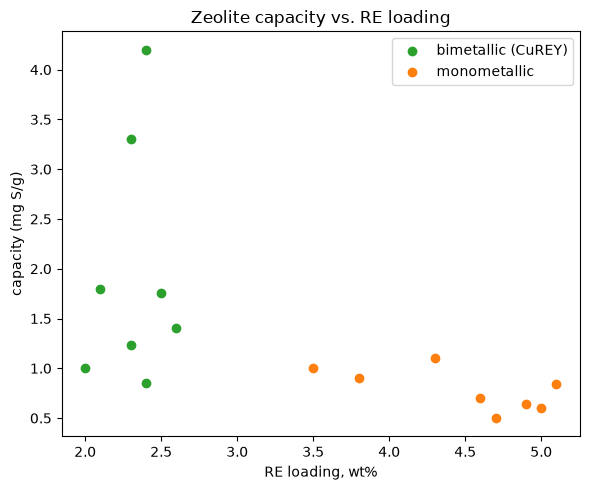

In [15]:
fig, ax = plt.subplots(figsize=(6,5))
colors = {'monometallic': 'tab:orange', 'bimetallic (CuREY)': 'tab:green'}
zeo_plot = zeo.copy()
zeo_plot['group'] = np.where(zeo_plot['Cu_wt_pct'] > 0, 'bimetallic (CuREY)', 'monometallic')
for grp, g in zeo_plot.groupby('group'):
    ax.scatter(g['RE_wt_pct'], g['capacity_mgS_g'], label=grp, color=colors[grp])
ax.set_xlabel('RE loading, wt%')
ax.set_ylabel('capacity (mg S/g)')
ax.legend()
ax.set_title('Zeolite capacity vs. RE loading')
plt.tight_layout()
plt.savefig('../reports/zeolite_capacity_vs_re_loading.png', dpi=120)
plt.show()

### Rare-earth identity and pore volume within each compound

RE loading, Cu loading and sorbent subclass are pooled across BT and DBT above. Rare-earth identity and pore volume are examined here within a single compound, which separates effects driven by the compound or sorbent class from effects of the metal.

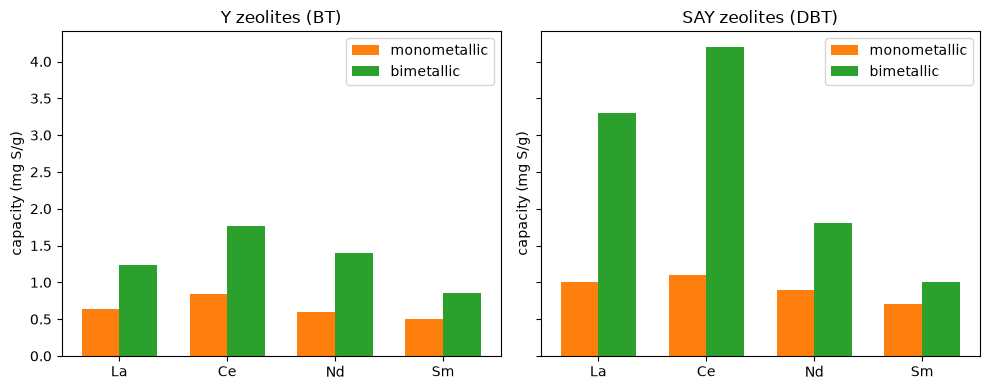

In [16]:
zeo_re = zeo.copy()
zeo_re['group'] = np.where(zeo_re['Cu_wt_pct'] > 0, 'bimetallic', 'monometallic')
re_order = ['La', 'Ce', 'Nd', 'Sm']

fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)
for ax, (cls, label) in zip(axes, [('zeolite_Y', 'Y zeolites (BT)'), ('zeolite_SAY', 'SAY zeolites (DBT)')]):
    sub = zeo_re[zeo_re['sorbent_class'] == cls]
    piv = sub.pivot_table(index='RE_type', columns='group', values='capacity_mgS_g').reindex(re_order)
    x = np.arange(len(re_order))
    width = 0.35
    ax.bar(x - width/2, piv['monometallic'], width, label='monometallic', color='tab:orange')
    ax.bar(x + width/2, piv['bimetallic'], width, label='bimetallic', color='tab:green')
    ax.set_xticks(x)
    ax.set_xticklabels(re_order)
    ax.set_title(label)
    ax.set_ylabel('capacity (mg S/g)')
    ax.legend()
plt.tight_layout()
plt.savefig('../reports/zeolite_capacity_by_re_type.png', dpi=120)
plt.show()

Ce had the highest capacity of the four rare earths in all four groups (Y monometallic, Y bimetallic, SAY monometallic, SAY bimetallic).

In [17]:
bt = zeo[zeo['sulfur_compound'] == 'BT']
dbt = zeo[zeo['sulfur_compound'] == 'DBT']
pore_feats = ['Vmicro_cm3g', 'Vmeso_cm3g', 'Vtotal_cm3g']
print(f"Pore volume vs. capacity, BT only (n={len(bt)}):")
print(bt[pore_feats].corrwith(bt['capacity_mgS_g']))
print()
print(f"Pore volume vs. capacity, DBT only (n={len(dbt)}):")
print(dbt[pore_feats].corrwith(dbt['capacity_mgS_g']))

Pore volume vs. capacity, BT only (n=8):
Vmicro_cm3g    0.521780
Vmeso_cm3g     0.628313
Vtotal_cm3g    0.668068
dtype: float64

Pore volume vs. capacity, DBT only (n=8):
Vmicro_cm3g   -0.048413
Vmeso_cm3g    -0.079358
Vtotal_cm3g   -0.113481
dtype: float64


Within DBT (SAY only), pore volume was essentially unrelated to capacity (r = -0.05 to -0.11). Within BT (Y only), pore volume showed a moderate positive association (r = 0.52 to 0.67), but Cu co-doping changes pore volume and capacity together (n = 8), so the pore-volume effect cannot be separated from the metal effect with these data.

### Rare-earth valence descriptor: 4f electron count

The relevant state of each rare earth is the one present immediately before sulfur adsorption, after reduction. In that state all four are trivalent (Ce is fully reduced to Ce3+, per the XANES results of Sokol et al., 2022), so the 4f electron count of the 3+ ion describes each rare earth. The configurations below are standard reference values, not measurements from the source papers.

In [18]:
re_ref = pd.DataFrame({
    'RE_type': ['La', 'Ce', 'Nd', 'Sm'],
    'ion': ['La3+', 'Ce3+', 'Nd3+', 'Sm3+'],
    'configuration': ['4f0', '4f1', '4f3', '4f5'],
    'RE_f_electrons': [0, 1, 3, 5],
}).set_index('RE_type')
re_ref

,ion,configuration,RE_f_electrons
RE_type,,,
La,La3+,4f0,0
Ce,Ce3+,4f1,1
Nd,Nd3+,4f3,3
Sm,Sm3+,4f5,5


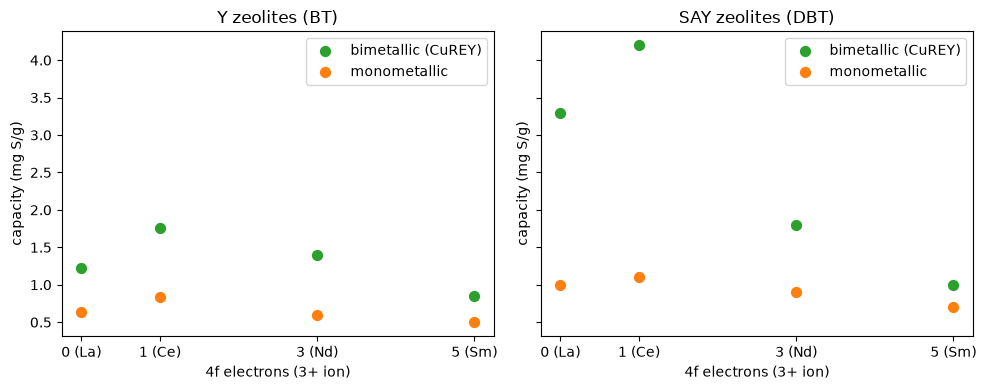

In [19]:
f_map = re_ref['RE_f_electrons'].to_dict()
zeo_f = zeo.copy()
zeo_f['f_electrons'] = zeo_f['RE_type'].map(f_map)
zeo_f['group'] = np.where(zeo_f['Cu_wt_pct'] > 0, 'bimetallic (CuREY)', 'monometallic')
colors_f = {'monometallic': 'tab:orange', 'bimetallic (CuREY)': 'tab:green'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (cls, label) in zip(axes, [('zeolite_Y', 'Y zeolites (BT)'), ('zeolite_SAY', 'SAY zeolites (DBT)')]):
    sub = zeo_f[zeo_f['sorbent_class'] == cls]
    for grp, g in sub.groupby('group'):
        ax.scatter(g['f_electrons'], g['capacity_mgS_g'], label=grp, color=colors_f[grp], s=50)
    ax.set_xticks([0, 1, 3, 5])
    ax.set_xticklabels(['0 (La)', '1 (Ce)', '3 (Nd)', '5 (Sm)'])
    ax.set_xlabel('4f electrons (3+ ion)')
    ax.set_title(label)
    ax.set_ylabel('capacity (mg S/g)')
    ax.legend()
plt.tight_layout()
plt.savefig('../reports/zeolite_capacity_vs_4f.png', dpi=120)
plt.show()

Capacity peaked at 4f1 (Ce) and was lower on both sides in all four groups. The pattern is a peak, not a monotonic trend, so a linear term in 4f count cannot represent it. With only four rare earths, the peak cannot be distinguished from Ce identity itself. It is therefore a description of the data and not evidence that the 4f1 configuration is causal.

## 6. Sulfur compound effect within a single material (activated carbons)

Several activated carbons were tested with both DBT and DMDBT on the same physical sample, which isolates the effect of the compound from the effect of the material.

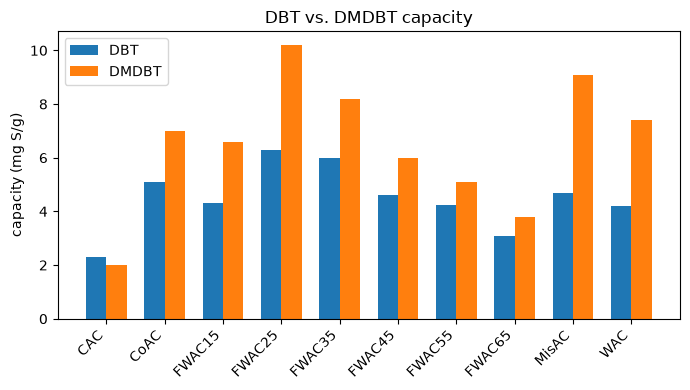

In [20]:
piv = ac.pivot_table(index='material', columns='sulfur_compound', values='capacity_mgS_g')
paired = piv.dropna(subset=['DBT','DMDBT'])
fig, ax = plt.subplots(figsize=(7,4))
x = np.arange(len(paired))
width = 0.35
ax.bar(x - width/2, paired['DBT'], width, label='DBT')
ax.bar(x + width/2, paired['DMDBT'], width, label='DMDBT')
ax.set_xticks(x)
ax.set_xticklabels(paired.index, rotation=45, ha='right')
ax.set_ylabel('capacity (mg S/g)')
ax.set_title('DBT vs. DMDBT capacity')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/dbt_vs_dmdbt.png', dpi=120)
plt.show()

DMDBT capacity was higher than DBT capacity for the same material in 9 of the 10 paired materials, by 0.7 to 4.4 mg S/g. The exception was CAC, where DMDBT capacity was 0.3 mg S/g lower.

## 7. Repeated materials and the evaluation design

The 10 activated carbons, among the 26 materials, contribute two rows each (one per sulfur compound), with identical textural and compositional features. Under row-level leave-one-out cross-validation, a model could see a material's properties through its DBT row while being tested on its DMDBT row. Evaluation therefore uses leave-one-material-out cross-validation.

In [21]:
dupe_materials = cap.groupby('material').size()
print("Rows per material (materials with >1 row need grouped CV):")
print(dupe_materials[dupe_materials > 1])

Rows per material (materials with >1 row need grouped CV):
material
CAC       2
CoAC      2
FWAC15    2
FWAC25    2
FWAC35    2
FWAC45    2
FWAC55    2
FWAC65    2
MisAC     2
WAC       2
dtype: int64


## Summary of findings

1. **Class balance**: 20 activated-carbon rows (10 distinct materials) and 16 zeolite rows (16 distinct materials).
2. **Confounding**: within the zeolite family, sulfur compound is confounded with sorbent subclass and with the co-adsorbate (benzene with BT on Y; naphthalene with DBT on SAY).
3. **Activated carbons**: the Raman D/G band ratio (`ID_IG_ratio`) showed the strongest association with capacity (r = 0.60 by row, 0.74 by material; 0.36 and 0.50 with the extreme low-capacity carbon CAC removed), followed by hydrogen content (r = -0.56), micropore volume and area (r = 0.52 and 0.51) and potassium content (r = 0.50). Carbon and nitrogen content showed almost no association. Visually, the scatter plots show no clean single-feature trend other than a noisy upward one for ID/IG.
4. **Zeolites**: in every rare-earth pairing, the bimetallic (CuREY) zeolite had higher capacity than its monometallic counterpart, although bimetallic samples also carried about half the RE loading. Ce had the highest capacity of the four rare earths in all four groups, a peak at 4f1 that a linear 4f-count term cannot represent. Pore volume was unrelated to capacity within DBT (r = -0.05 to -0.11); within BT it showed a moderate positive association (r = 0.52 to 0.67) that is confounded with Cu co-doping at n = 8.
5. **DMDBT capacity exceeded DBT capacity** for the same material in 9 of 10 pairs (by 0.7 to 4.4 mg S/g).
6. **Repeated materials**: 10 of 26 materials appear under both sulfur compounds, so evaluation uses leave-one-material-out cross-validation.